In [16]:
import scipy.io
import numpy as np
from matplotlib import pyplot as plt

In [34]:
path = r"Zakir_standing\P01A\P01A1\IQ"
data = scipy.io.loadmat(path)

In [35]:
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'Data_IQ'])


In [36]:
print(data['Data_IQ'])

[[ 8.10500979e-03-1.71877793e-03j  5.82853844e-03-9.42554383e-04j
   5.12621505e-03+5.17382694e-04j ...  8.39732093e-06+3.73391558e-05j
   6.96319403e-05+5.01645154e-05j  2.97396800e-05+3.30906296e-05j]
 [ 8.10768269e-03-1.71981519e-03j  5.84186241e-03-9.25719854e-04j
   5.08706085e-03+5.61643159e-04j ...  9.87333442e-06+2.67876530e-05j
   4.97456494e-05+2.82437195e-05j -2.29978887e-05+3.09962852e-05j]
 [ 8.09084810e-03-1.77301152e-03j  5.84561238e-03-9.57873010e-04j
   5.15396055e-03+5.38705091e-04j ... -1.67946419e-05+7.54362627e-05j
   9.61403475e-06+6.34286916e-05j -4.60556148e-05+1.42814288e-05j]
 ...
 [ 5.54636074e-03-1.44475605e-02j  2.30282056e-03-2.53343377e-02j
   2.84717046e-03-2.62631699e-02j ...  1.13513430e-04+1.30746877e-04j
   6.54432515e-05+2.64066824e-04j -2.26986958e-05+2.11648381e-04j]
 [ 5.59177808e-03-1.43817384e-02j  2.38045095e-03-2.52595190e-02j
   2.87974253e-03-2.61460450e-02j ...  1.42674675e-04+1.61623495e-04j
   8.67457202e-05+2.38914741e-04j  9.11538154e-

In [37]:
I = np.real(data["Data_IQ"])
Q = np.imag(data["Data_IQ"])

In [38]:
I

array([[ 8.10500979e-03,  5.82853844e-03,  5.12621505e-03, ...,
         8.39732093e-06,  6.96319403e-05,  2.97396800e-05],
       [ 8.10768269e-03,  5.84186241e-03,  5.08706085e-03, ...,
         9.87333442e-06,  4.97456494e-05, -2.29978887e-05],
       [ 8.09084810e-03,  5.84561238e-03,  5.15396055e-03, ...,
        -1.67946419e-05,  9.61403475e-06, -4.60556148e-05],
       ...,
       [ 5.54636074e-03,  2.30282056e-03,  2.84717046e-03, ...,
         1.13513430e-04,  6.54432515e-05, -2.26986958e-05],
       [ 5.59177808e-03,  2.38045095e-03,  2.87974253e-03, ...,
         1.42674675e-04,  8.67457202e-05,  9.11538154e-06],
       [ 5.63637726e-03,  2.41932599e-03,  2.86717643e-03, ...,
         1.45028316e-04,  9.02163447e-05,  5.68464702e-06]])

In [39]:
magnitude = np.sqrt(I**2+Q**2)
phase = np.arctan2(Q,I)

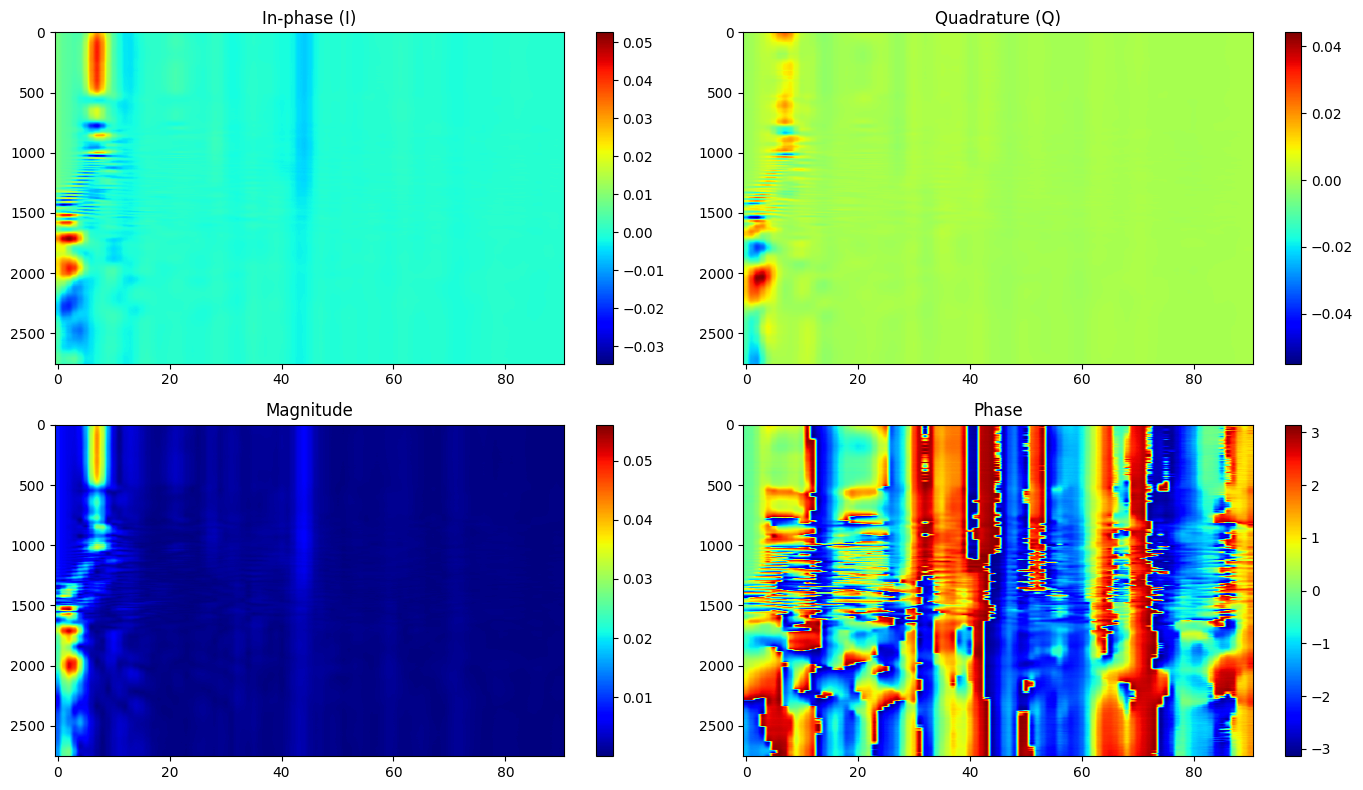

In [40]:
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(I, aspect='auto', cmap='jet')
plt.title('In-phase (I)')
plt.colorbar()

plt.subplot(2, 2, 2)
plt.imshow(Q, aspect='auto', cmap='jet')
plt.title('Quadrature (Q)')
plt.colorbar()

plt.subplot(2, 2, 3)
plt.imshow(magnitude, aspect='auto', cmap='jet')
plt.title('Magnitude')
plt.colorbar()

plt.subplot(2, 2, 4)
plt.imshow(phase, aspect='auto', cmap='jet')
plt.title('Phase')
plt.colorbar()

plt.tight_layout()
plt.show()

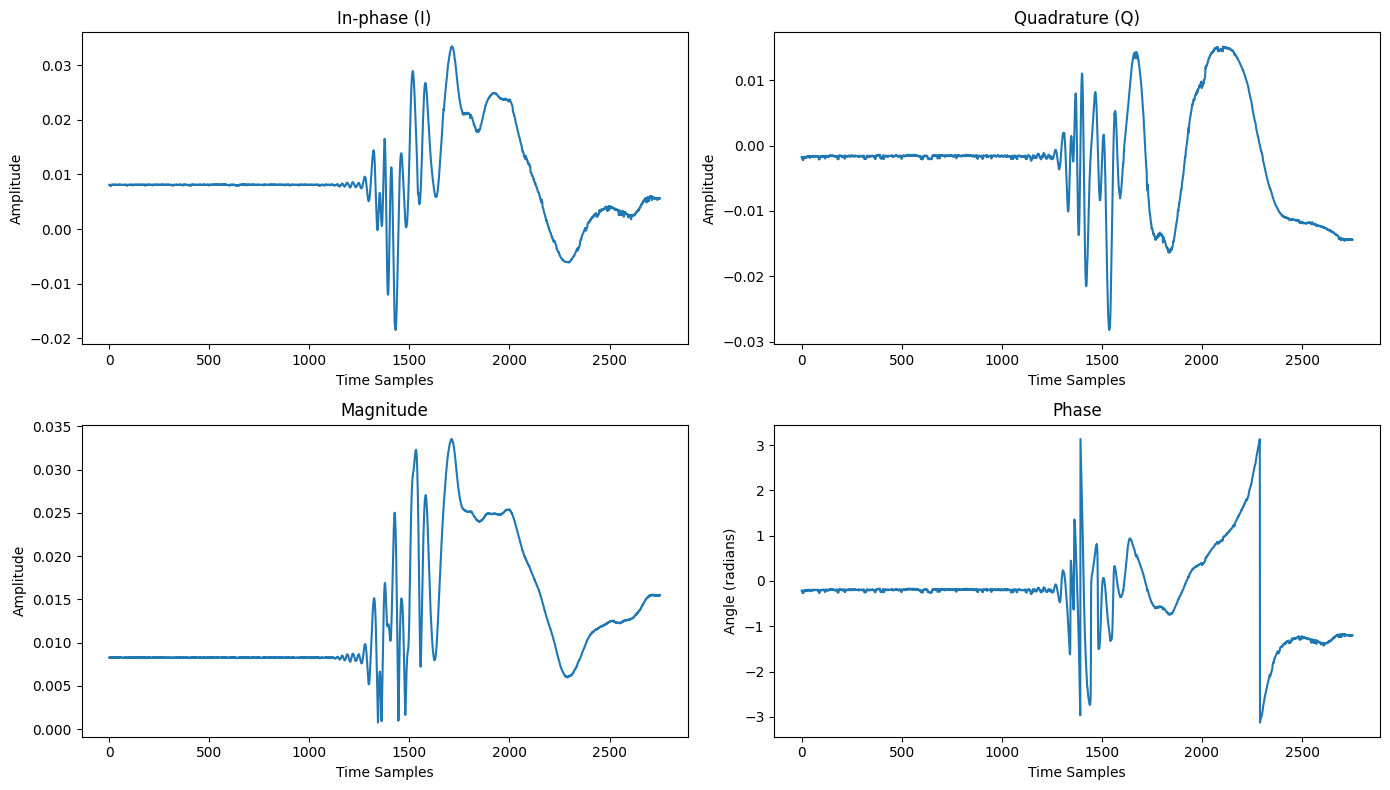

In [41]:
range_bin_to_plot = 0 

plt.figure(figsize=(14, 8))

# Plotting I component
plt.subplot(2, 2, 1)
plt.plot(I[:, range_bin_to_plot])
plt.title('In-phase (I)')
plt.xlabel('Time Samples')
plt.ylabel('Amplitude')

# Plotting Q component
plt.subplot(2, 2, 2)
plt.plot(Q[:, range_bin_to_plot])
plt.title('Quadrature (Q)')
plt.xlabel('Time Samples')
plt.ylabel('Amplitude')

# Plotting Magnitude
plt.subplot(2, 2, 3)
plt.plot(magnitude[:, range_bin_to_plot])
plt.title('Magnitude')
plt.xlabel('Time Samples')
plt.ylabel('Amplitude')

# Plotting Phase
plt.subplot(2, 2, 4)
plt.plot(phase[:, range_bin_to_plot])
plt.title('Phase')
plt.xlabel('Time Samples')
plt.ylabel('Angle (radians)')

plt.tight_layout()
plt.show()


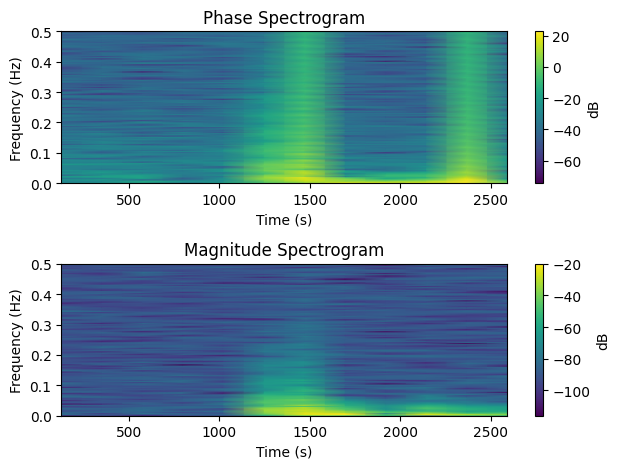

In [42]:
from scipy.signal import spectrogram

plt.subplot(2, 1, 1)
f, t, Sxx = spectrogram(phase[:, range_bin_to_plot], fs=1.0)  # Assuming a sample rate of 1.0;
plt.pcolormesh(t, f, 10 * np.log10(Sxx), shading='gouraud')
plt.colorbar(label='dB')
plt.ylabel('Frequency (Hz)')
plt.xlabel('Time (s)')
plt.title('Phase Spectrogram')

plt.subplot(2, 1, 2)
f, t, Sxx = spectrogram(magnitude[:, range_bin_to_plot], fs=1.0)  # Assuming a sample rate of 1.0;
plt.pcolormesh(t, f, 10 * np.log10(Sxx), shading='gouraud')
plt.colorbar(label='dB')
plt.ylabel('Frequency (Hz)')
plt.xlabel('Time (s)')
plt.title('Magnitude Spectrogram')


plt.tight_layout()
plt.show()
